# MUC02 — Credit Pre-Screening Engine
**Calibo AI Academy · Path 2 · KLU Batch5**  

## CBIM Problem Canvas

### 1. Situation
A private bank receives approximately 3,000 unsecured personal-loan applications each month. Each application currently receives a manual credit review taking about 25 minutes.

### 2. Complication
Manual reviews consume analyst capacity, including applications that may be clear-cut declines under historical policy. An unsafe automated decision could wrongly reject a creditworthy applicant, so reducing workload must be balanced against customer risk.

### 3. Question
Can six months of historical decisions support a cautious pre-screening model that routes only high-confidence predicted declines away from the manual-review queue while keeping historically approved applicants to no more than 5% of the auto-decline group?

### 4. SSOT — Single Source of Truth
The provided `MUC02_Credit_PreScreening_Dataset 1.csv` is the source for this analysis. The `decision` column records the credit team's historical final decision (`Approved` or `Declined`). It does not indicate whether a loan was actually repaid.

### 5. Success definition
Choose the lowest tested probability threshold for which no more than 5% of auto-declined test applications were historically approved, then translate the auto-decline rate into estimated monthly applications and analyst hours.

### 6. Primary stakeholder
The primary stakeholder is the Credit Policy Analyst, who will brief the Head of Retail Lending. Credit analysts and loan applicants are also directly affected by any proposed policy.

> **Scope note:** This is an educational model based on historical decisions, not a production credit decision system. It requires independent validation, repayment/default outcomes, policy approval and human oversight before any real-world use.


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [6]:
from pathlib import Path

DATA_FILE = Path("MUC02_Credit_PreScreening_Dataset 1.csv")
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_FILE.resolve()}. "
        "Place the CSV in the same folder as this notebook."
    )

df = pd.read_csv(DATA_FILE)

print("Shape:", df.shape)
display(df.head())
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print("\nDecision counts:")
display(df["decision"].value_counts())

print("\nApproval rate:")
print((df["decision"] == "Approved").mean() * 100)

Shape: (12000, 19)


,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision
0,APP100001,2026-04-01,28,Male,Hyderabad,1,Salaried,4.1,95000.0,23500.0,784.0,109,2,0,Home Renovation,240000.0,48,6600.0,Approved
1,APP100002,2026-04-01,36,Female,Raipur,3,Business Owner,0.6,43000.0,8500.0,790.0,162,2,0,Wedding,145000.0,36,5000.0,Approved
2,APP100003,2026-04-01,35,Male,Nagpur,2,Salaried,4.4,35000.0,3500.0,718.0,151,1,1,Medical,345000.0,36,11800.0,Approved
3,APP100004,2026-04-01,42,Male,Jaipur,2,Salaried,5.8,44500.0,0.0,NaN,0,0,0,Travel,135000.0,36,4600.0,Approved
4,APP100005,2026-04-01,34,Male,Kochi,2,Self-Employed Professional,2.1,83500.0,6000.0,700.0,127,1,3,Medical,700000.0,24,33600.0,Declined


<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   application_id         12000 non-null  str    
 1   application_date       12000 non-null  str    
 2   age                    12000 non-null  int64  
 3   gender                 12000 non-null  str    
 4   city                   12000 non-null  str    
 5   city_tier              12000 non-null  int64  
 6   employment_type        12000 non-null  str    
 7   years_in_current_job   12000 non-null  float64
 8   monthly_income         11559 non-null  float64
 9   existing_emi           12000 non-null  float64
 10  credit_score           10961 non-null  float64
 11  credit_history_months  12000 non-null  int64  
 12  num_active_loans       12000 non-null  int64  
 13  delinquencies_24m      12000 non-null  int64  
 14  loan_purpose           12000 non-null  str    
 15  loan_amount  

application_id              0
application_date            0
age                         0
gender                      0
city                        0
city_tier                   0
employment_type             0
years_in_current_job        0
monthly_income            441
existing_emi                0
credit_score             1039
credit_history_months       0
num_active_loans            0
delinquencies_24m           0
loan_purpose                0
loan_amount                 0
tenure_months               0
proposed_emi                0
decision                    0
dtype: int64


Decision counts:


decision
Approved    6353
Declined    5647
Name: count, dtype: int64


Approval rate:
52.94166666666666


### Initial dataset interpretation
The dataset contains 12,000 applications across April–September 2026, with 19 columns. The target is the historical credit team's decision, not whether a loan was repaid. The overall approval rate helps describe the target balance, but it is not the model's success criterion. For this use case, the most important operational measure is the percentage of historically Approved applicants inside the proposed auto-decline group.

In [7]:
missing_income = df[df["monthly_income"].isna()]

print("Missing income rows:", len(missing_income))

display(
    missing_income["employment_type"].value_counts()
)

display(
    df.groupby("employment_type")["monthly_income"]
      .apply(lambda s: s.isna().mean() * 100)
      .round(2)
)

Missing income rows: 441


employment_type
Business Owner                227
Self-Employed Professional    154
Salaried                       49
Gig / Contract                 11
Name: count, dtype: int64

employment_type
Business Owner                12.98
Gig / Contract                 0.62
Salaried                       0.69
Self-Employed Professional    10.78
Name: monthly_income, dtype: float64

### Step 5.1 — Missing income investigation
This cell identifies how many income values are missing and which employment types are affected. Missing income should not be treated as random without checking its pattern. The chosen treatment is the median monthly income within each employment type, documented below.

In [8]:
no_score = df[df["credit_score"].isna()]

print("Missing credit scores:", len(no_score))

display(no_score["credit_history_months"].value_counts())

Missing credit scores: 1039


credit_history_months
0    1039
Name: count, dtype: int64

### Step 5.1 — Missing credit scores
The assignment says to retain applicants with missing credit scores. Check whether their `credit_history_months` is zero. In this dataset, blank scores represent new-to-credit applicants; the `is_ntc` flag preserves this information instead of dropping those applicants.

In [9]:
print("Maximum income:", df["monthly_income"].max())

display(
    df.loc[df["monthly_income"] > 600000,
           ["employment_type", "monthly_income"]]
)

Maximum income: 1656000.0


,employment_type,monthly_income
300,Salaried,1254000.0
589,Salaried,1068000.0
1467,Salaried,1656000.0
1848,Salaried,984000.0
2488,Salaried,972000.0
2493,Salaried,1212000.0
4010,Salaried,900000.0
4898,Salaried,870000.0
7426,Salaried,690000.0
8381,Salaried,618000.0


### Step 5.1 — Implausible income values
The expected-outcomes material identifies 12 Salaried records above ₹6,00,000 monthly income as likely annual salaries entered as monthly income. The next cell divides these values by 12. This is an assumption for the exercise and should be recorded in the cleaning log.

In [10]:
# Correct the likely annual-income entries.
high_income = df["monthly_income"] > 600000

df.loc[high_income, "monthly_income"] /= 12

print("High-income entries adjusted:", high_income.sum())

# Preserve the missing-credit-score information.
df["is_ntc"] = df["credit_score"].isna().astype(int)

# Fill missing income with the median for each employment type.
income_medians = df.groupby(
    "employment_type"
)["monthly_income"].transform("median")

df["monthly_income"] = df["monthly_income"].fillna(
    income_medians
)

print("Remaining missing income:", df["monthly_income"].isna().sum())
print("Missing credit scores retained:", df["credit_score"].isna().sum())

High-income entries adjusted: 12
Remaining missing income: 0
Missing credit scores retained: 1039


### Step 5.1 — Cleaning decisions and rationale
- **Missing monthly income:** impute with the median for the same employment type to retain rows while respecting different income distributions.
- **Missing credit score:** retain the rows and create `is_ntc = 1`; the model pipeline later imputes the numeric score using the training-set median.
- **Very high monthly income:** divide the 12 values above ₹6 lakh by 12, following the expected-outcomes guidance that they likely represent annual salary entered in a monthly field.
- **Important:** these are documented assumptions for a simulated dataset. In a live lending workflow, confirm income units with the source system before correcting records.

Check the printed counts and confirm no income values remain missing.

score_band
Below 600     2.0
600–649       3.2
650–699      32.5
700–749      54.4
750–799      77.2
800+         85.2
No score     53.9
Name: approved, dtype: float64

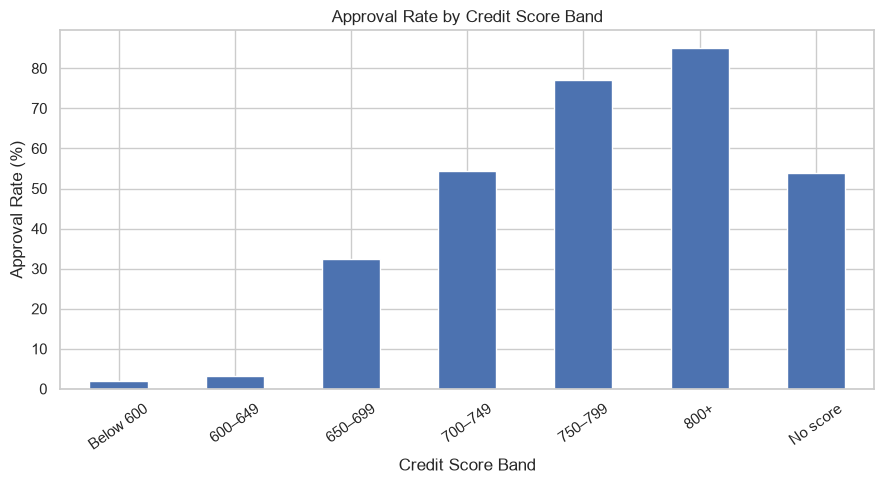

In [11]:
score_bins = [-np.inf, 599, 649, 699, 749, 799, np.inf]

score_labels = [
    "Below 600", "600–649", "650–699",
    "700–749", "750–799", "800+"
]

df["score_band"] = pd.cut(
    df["credit_score"],
    bins=score_bins,
    labels=score_labels
)

df["score_band"] = (
    df["score_band"].cat.add_categories(["No score"])
)

df.loc[df["credit_score"].isna(), "score_band"] = "No score"

score_approval = (
    df.assign(approved=(df["decision"] == "Approved"))
      .groupby("score_band", observed=False)["approved"]
      .mean() * 100
)

display(score_approval.round(1))

score_approval.plot(kind="bar", figsize=(9, 5))
plt.title("Approval Rate by Credit Score Band")
plt.xlabel("Credit Score Band")
plt.ylabel("Approval Rate (%)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

### Step 5.2 — Approval rate by credit-score band
The chart shows the historical proportion approved in each score band, including a separate `No score` group. The expected-outcomes reference shows that approvals are very uncommon below 650, rise around the 650–699 band, and remain meaningful for applicants without scores. This suggests a strong historical score pattern, but not a sufficient reason to automatically reject every low-score or new-to-credit applicant.

employment_type
Business Owner                51.2
Gig / Contract                34.9
Salaried                      58.4
Self-Employed Professional    50.6
Name: approved, dtype: float64

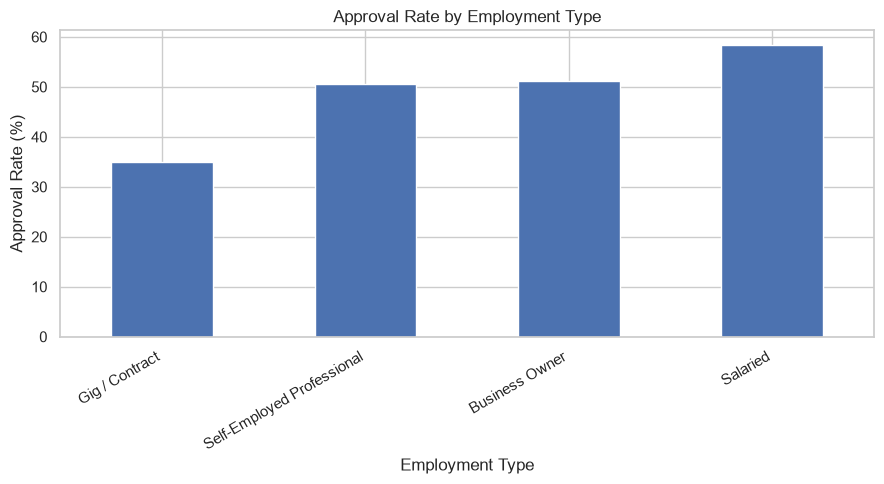

In [12]:
employment_approval = (
    df.assign(approved=(df["decision"] == "Approved"))
      .groupby("employment_type")["approved"]
      .mean() * 100
)

display(employment_approval.round(1))

employment_approval.sort_values().plot(
    kind="bar", figsize=(9, 5)
)

plt.title("Approval Rate by Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Approval Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Step 5.2 — Approval rate by employment type
Compare approval rates across employment types. The reference deck reports a higher approval rate for Salaried applicants than for Gig / Contract workers. Differences may reflect income stability, affordability or historical policy; they should not be interpreted as proof that employment type itself causes repayment outcomes.

In [13]:
df["foir"] = (
    df["existing_emi"] + df["proposed_emi"]
) / df["monthly_income"]

df["loan_to_income"] = (
    df["loan_amount"] / (df["monthly_income"] * 12)
)

df["is_ntc"] = df["credit_score"].isna().astype(int)

display(
    df[[
        "monthly_income", "existing_emi", "proposed_emi",
        "foir", "loan_to_income", "is_ntc"
    ]].head()
)

,monthly_income,existing_emi,proposed_emi,foir,loan_to_income,is_ntc
0,95000.0,23500.0,6600.0,0.316842,0.210526,0
1,43000.0,8500.0,5000.0,0.313953,0.281008,0
2,35000.0,3500.0,11800.0,0.437143,0.821429,0
3,44500.0,0.0,4600.0,0.103371,0.252809,1
4,83500.0,6000.0,33600.0,0.474251,0.698603,0


### Step 5.3 — Feature engineering
`foir` is the share of monthly income committed to existing and proposed EMIs. `loan_to_income` compares the requested loan amount with annual income. `is_ntc` distinguishes applicants with no credit score. These derived features represent affordability and credit-history context that are not captured by monthly income alone.

foir_band
Below 30%    65.4
30–40%       59.0
40–50%       47.4
50–55%       31.7
Above 55%    15.5
Name: approved, dtype: float64

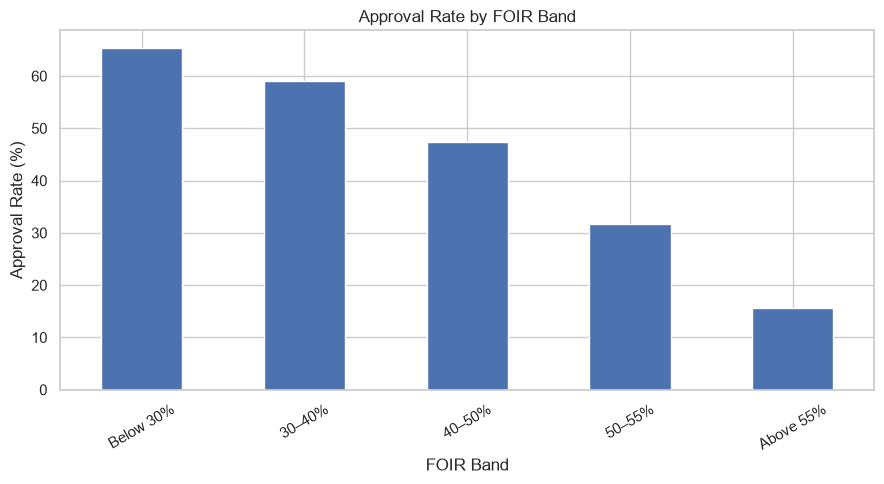

In [14]:
foir_bins = [-np.inf, 0.30, 0.40, 0.50, 0.55, np.inf]

foir_labels = [
    "Below 30%", "30–40%", "40–50%",
    "50–55%", "Above 55%"
]

df["foir_band"] = pd.cut(
    df["foir"],
    bins=foir_bins,
    labels=foir_labels
)

foir_approval = (
    df.assign(approved=(df["decision"] == "Approved"))
      .groupby("foir_band", observed=False)["approved"]
      .mean() * 100
)

display(foir_approval.round(1))

foir_approval.plot(kind="bar", figsize=(9, 5))
plt.title("Approval Rate by FOIR Band")
plt.xlabel("FOIR Band")
plt.ylabel("Approval Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Step 5.3 — FOIR interpretation
The FOIR chart should show how historical approval rates change as repayment obligations consume a larger share of income. The reference deck reports a fall from about 65.4% approval below 30% FOIR to 15.5% above 55%, with a sharp decline after 50%. Use your own displayed values in the final write-up. A 50–55% range is a candidate for further policy review, not a universal lending rule.

In [15]:
features = [
    "credit_score",
    "is_ntc",
    "foir",
    "loan_to_income",
    "delinquencies_24m",
    "num_active_loans",
    "years_in_current_job",
    "age",
    "tenure_months",
    "city_tier",
    "employment_type",
    "loan_purpose"
]

X = df[features].copy()

y = (df["decision"] == "Declined").astype(int)

print("Target counts:")
print(y.value_counts())

Target counts:
decision
0    6353
1    5647
Name: count, dtype: int64


### Step 5.4 — Target and features
The target is `1` for `Declined` and `0` for `Approved`, because the model is estimating decline probability. The selected features follow the assignment. `gender`, `city`, identifiers, application date and the target itself are not used as predictors. Gender is still analysed separately for the required fairness check.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 9600
Test rows: 2400


### Step 5.4 — Train/test split
The 80/20 split produces 9,600 training rows and 2,400 test rows. Stratification keeps the Approved/Declined class proportions similar across the sets. `random_state=42` makes the split reproducible for comparison.

In [17]:
numeric_features = [
    "credit_score",
    "is_ntc",
    "foir",
    "loan_to_income",
    "delinquencies_24m",
    "num_active_loans",
    "years_in_current_job",
    "age",
    "tenure_months",
    "city_tier"
]

categorical_features = [
    "employment_type",
    "loan_purpose"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline([
                ("imputer", __import__(
                    "sklearn.impute",
                    fromlist=["SimpleImputer"]
                ).SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


### Step 5.4 — Preprocessing and model
The preprocessing pipeline imputes missing numeric values, scales numeric features, and one-hot encodes `employment_type` and `loan_purpose`. The logistic regression model is trained only on the training split. Keeping preprocessing inside the pipeline helps prevent the test set from influencing imputation or scaling.

In [18]:
y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=["Approved", "Declined"]
))

decline_prob = model.predict_proba(X_test)[:, 1]

print("ROC-AUC:", round(
    roc_auc_score(y_test, decline_prob), 4
))

Accuracy: 0.7908

Confusion Matrix:
[[1046  225]
 [ 277  852]]

Classification Report:
              precision    recall  f1-score   support

    Approved       0.79      0.82      0.81      1271
    Declined       0.79      0.75      0.77      1129

    accuracy                           0.79      2400
   macro avg       0.79      0.79      0.79      2400
weighted avg       0.79      0.79      0.79      2400

ROC-AUC: 0.8674


### Step 5.4 — Model evaluation
Read the confusion matrix with actual decisions in rows and predicted decisions in columns. With labels `[0, 1]`, the top-right cell counts historically Approved applicants predicted as Declined: these are the potentially wrongly declined customers of greatest concern. Accuracy alone is not enough; also report Declined-class precision/recall and ROC-AUC. The model predicts historical decisions, not actual repayment/default.

### Step 5.4 — Check model performance for new-to-credit (NTC) applicants

Overall accuracy can hide weak performance for a smaller customer group. Because missing credit scores identify NTC applicants in this dataset, compare accuracy on NTC and non-NTC test records separately. This is a diagnostic, not proof of fairness or creditworthiness.

In [19]:
# Compare held-out accuracy for applicants with and without recorded credit history.
test_is_ntc = df.loc[X_test.index, "is_ntc"].eq(1)

for group_name, mask in [
    ("NTC", test_is_ntc),
    ("Non-NTC", ~test_is_ntc)
]:
    group_accuracy = accuracy_score(y_test.loc[mask], y_pred[mask])
    print(
        f"{group_name}: n={int(mask.sum())}, "
        f"accuracy={group_accuracy:.1%}"
    )


NTC: n=203, accuracy=56.7%
Non-NTC: n=2197, accuracy=81.2%


In [20]:
feature_names = (
    model.named_steps["preprocessor"]
    .get_feature_names_out()
)

coefficients = model.named_steps["model"].coef_[0]

coef_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

coef_table["abs_coefficient"] = (
    coef_table["coefficient"].abs()
)

display(
    coef_table.sort_values(
        "abs_coefficient", ascending=False
    ).head(5)
)

,feature,coefficient,abs_coefficient
2,numeric__foir,1.219570,1.219570
0,numeric__credit_score,-1.009794,1.009794
4,numeric__delinquencies_24m,0.978713,0.978713
11,categorical__employment_type_Gig / Contract,0.618781,0.618781
12,categorical__employment_type_Salaried,-0.444486,0.444486


### Step 5.4 — Coefficient interpretation
Positive coefficients push the model toward predicting `Declined`; negative coefficients push it toward `Approved`, holding other model inputs constant. The numeric inputs are scaled, so coefficient magnitudes can be compared more meaningfully across numeric variables. One-hot encoded categories are relative to their reference categories. These are associations in historical decisions, not causal effects.

In [21]:
thresholds = [0.50, 0.60, 0.70, 0.80, 0.85, 0.90, 0.95]

results = []

for threshold in thresholds:
    predicted_decline = decline_prob >= threshold

    total_auto_declined = predicted_decline.sum()

    auto_decline_pct = (
        predicted_decline.mean() * 100
    )

    if total_auto_declined > 0:
        # y_test = 0 means the historical decision was Approved.
        wrongly_declined = (
            (y_test.to_numpy() == 0) & predicted_decline
        ).sum()

        wrong_pct = (
            wrongly_declined / total_auto_declined * 100
        )
    else:
        wrong_pct = np.nan

    results.append({
        "Threshold": threshold,
        "Auto-declined (%)": auto_decline_pct,
        "Wrongly declined (%)": wrong_pct
    })

threshold_results = pd.DataFrame(results)

display(threshold_results.round(2))

,Threshold,Auto-declined (%),Wrongly declined (%)
0,0.50,44.88,20.89
1,0.60,37.62,16.83
2,0.70,30.75,12.06
3,0.80,23.46,7.10
4,0.85,19.67,5.93
5,0.90,15.21,4.66
6,0.95,10.00,2.08


### Step 5.5 — Threshold table
For each probability threshold, this cell calculates (1) the percentage of all test applications routed to the auto-decline lane and (2) the percentage of that lane that the historical team actually Approved. The second percentage is the risk measure required by the assignment. As the threshold rises, the lane normally becomes smaller and more conservative.

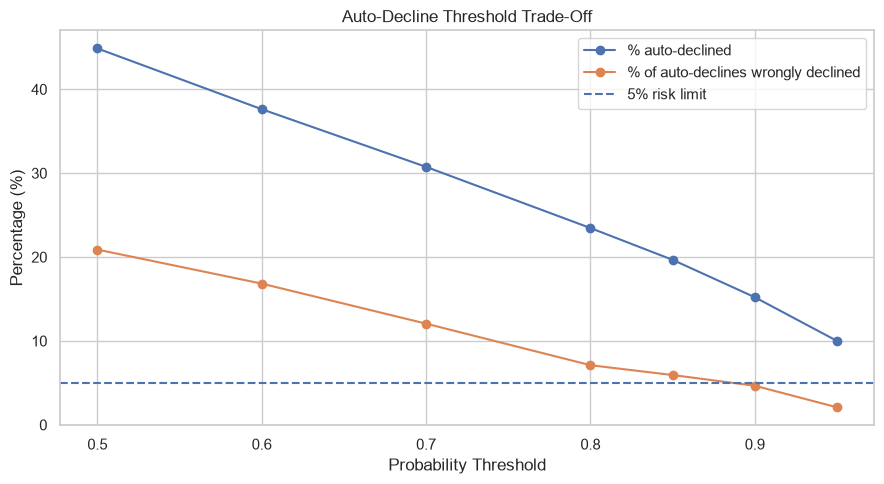

In [22]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Auto-declined (%)"],
    marker="o",
    label="% auto-declined"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Wrongly declined (%)"],
    marker="o",
    label="% of auto-declines wrongly declined"
)

plt.axhline(
    5, linestyle="--",
    label="5% risk limit"
)

plt.xlabel("Probability Threshold")
plt.ylabel("Percentage (%)")
plt.title("Auto-Decline Threshold Trade-Off")
plt.legend()
plt.tight_layout()
plt.show()

### Step 5.5 — Threshold trade-off chart
The chart compares operational volume with the wrong-decline rate and includes the bank's 5% limit. A suitable threshold must satisfy the risk constraint; do not choose 0.50 by default.

In [23]:
eligible = threshold_results[
    threshold_results["Wrongly declined (%)"] <= 5
]

if eligible.empty:
    print("No tested threshold satisfies the 5% risk limit.")
else:
    recommended = eligible.iloc[0]

    print("Recommended threshold:", recommended["Threshold"])
    print("Auto-declined:", round(
        recommended["Auto-declined (%)"], 2
    ), "%")
    print("Wrongly declined:", round(
        recommended["Wrongly declined (%)"], 2
    ), "%")

Recommended threshold: 0.9
Auto-declined: 15.21 %
Wrongly declined: 4.66 %


### Step 5.5 — Threshold and monthly business impact
The selected threshold is the lowest tested threshold that satisfies the 5% limit, maximizing auto-decline volume among the tested choices. Convert the test-set auto-decline percentage to the monthly scenario using 3,000 applications and 25 minutes per manual review. The result is an estimate of review time potentially freed, not guaranteed staff-hour savings.

In [24]:
df["approved_flag"] = (
    df["decision"] == "Approved"
).astype(int)

print("Overall approval rate by gender:")
display(
    df.groupby("gender")["approved_flag"]
      .mean().mul(100).round(2)
)

print("\nApproval rate by gender and employment type:")
gender_employment = (
    df.groupby(["employment_type", "gender"])["approved_flag"]
      .mean().mul(100).round(2)
)

display(gender_employment.unstack())

Overall approval rate by gender:


gender
Female    50.43
Male      54.10
Name: approved_flag, dtype: float64


Approval rate by gender and employment type:


gender,Female,Male
employment_type,,
Business Owner,51.62,51.05
Gig / Contract,34.65,35.18
Salaried,56.79,59.06
Self-Employed Professional,47.63,51.97


### Step 5.6 — Historical approval by gender
Compare overall approval rates and approval rates within each employment type. A gap in overall rates may partly reflect differences in employment mix or income, so examine the within-group results too. Excluding gender from model features is necessary for this exercise but does not, by itself, prove fairness.

In [25]:
gender_summary = df.groupby("gender").agg(
    median_income=("monthly_income", "median"),
    application_count=("gender", "size")
)

gender_summary["gig_worker_pct"] = (
    df.assign(
        is_gig=df["employment_type"].eq("Gig / Contract")
    )
    .groupby("gender")["is_gig"]
    .mean() * 100
)

display(gender_summary.round(2))

,median_income,application_count,gig_worker_pct
gender,,,
Female,45000.0,3795,21.37
Male,55000.0,8205,11.64


### Step 5.6 — Income and employment mix by gender
Compare median monthly income and the share of Gig / Contract workers. These differences can help interpret historical approval gaps, but they do not establish that a gap is justified or fair. Income and employment type can also act as proxies, so monitor model outcomes across groups.

In [26]:
if not eligible.empty:
    threshold = float(recommended["Threshold"])

    test_fairness = df.loc[X_test.index, ["gender"]].copy()

    test_fairness["auto_declined"] = (
        decline_prob >= threshold
    )

    fairness_rates = (
        test_fairness.groupby("gender")["auto_declined"]
        .mean() * 100
    )

    print("Auto-decline rate by gender:")
    display(fairness_rates.round(2))

Auto-decline rate by gender:


gender
Female    15.60
Male      15.03
Name: auto_declined, dtype: float64

### Step 5.6 — Auto-decline rate by gender
This compares the proportion of test applicants routed to the auto-decline lane at the selected threshold. In your written interpretation, state whether the rates differ, whether the model appears to widen or narrow the historical gap, and why continued monitoring is still needed. The model should not make a final automated lending decision based only on this educational analysis.

## Step 5.7 — Credit Policy Briefing

The lowest tested threshold satisfying the assignment's 5% wrong-decline constraint is **0.90**: on the test set it routes **15.21%** of applications to the proposed auto-decline lane, and **4.66%** of that lane were historically Approved. At 3,000 applications per month, this represents approximately **456 applications** and **190 analyst hours** of manual-review capacity potentially freed, assuming 25 minutes per review. The strongest fitted-model coefficients are FOIR (**+1.22**, pushes toward predicted Declined) and credit score (**−1.01**, pushes toward predicted Approved); historically, approval is about **3.0% below a credit score of 650** and **15.5% above 55% FOIR**. Keep new-to-credit applicants with human reviewers because test accuracy is much weaker for NTC applicants (**56.7%**) than for applicants with recorded credit scores (**81.2%**). Gender was excluded from predictors, but income and employment type may act as proxies, so monitor outcomes by gender and employment group; before real deployment, validate against repayment/default outcomes and obtain independent and policy review because this model predicts historical decisions, not true credit risk.
